In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
import pandas as pd

df = pd.read_csv("ai_jobs_market_2025_2026.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [14]:
print("Dataset shape:", df.shape)

print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (1500, 25)

Number of rows: 1500
Number of columns: 25

Column names:
['job_id', 'job_title', 'job_category', 'experience_level', 'years_of_experience', 'education_required', 'annual_salary_usd', 'salary_min_usd', 'salary_max_usd', 'city', 'country', 'remote_work', 'company_size', 'industry', 'required_skills', 'ai_salary_premium_pct', 'demand_score', 'demand_growth_yoy_pct', 'benefits_score_10', 'posting_year', 'posting_month', 'is_senior', 'is_remote_friendly', 'is_llm_role', 'salary_tier']


In [15]:
df.head()

,job_id,job_title,job_category,experience_level,years_of_experience,education_required,annual_salary_usd,salary_min_usd,salary_max_usd,city,...,ai_salary_premium_pct,demand_score,demand_growth_yoy_pct,benefits_score_10,posting_year,posting_month,is_senior,is_remote_friendly,is_llm_role,salary_tier
0,AIJOB0001,AI Agent Developer,AI Engineering,Senior (6-9 yrs),7,Master's,239000.0,155000,290000,Boston,...,13.1,96,16.9,6.8,2026,3,1,0,1,Senior ($200-300k)
1,AIJOB0002,Prompt Engineer,AI Engineering,Senior (6-9 yrs),2,Bachelor's,166000.0,90000,200000,London,...,5.4,82,11.6,6.2,2026,1,1,1,1,Upper-Mid ($150-200k)
2,AIJOB0003,LLM Engineer,AI Engineering,Senior (6-9 yrs),4,Associate's,360000.0,160000,300000,Seattle,...,9.1,98,42.7,7.7,2026,1,1,1,1,Elite (>$300k)
3,AIJOB0004,Data Engineer (AI),Data Engineering,Senior (6-9 yrs),3,Bachelor's,161000.0,130000,220000,Singapore,...,12.0,88,6.7,9.5,2026,3,1,1,0,Upper-Mid ($150-200k)
4,AIJOB0005,AI Product Manager,Product,Lead (10+ yrs),5,Bootcamp/Self-taught,283000.0,140000,260000,Los Angeles,...,9.4,85,17.3,8.9,2026,1,1,1,0,Senior ($200-300k)


In [16]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   job_id                 1500 non-null   object 
 1   job_title              1500 non-null   object 
 2   job_category           1500 non-null   object 
 3   experience_level       1500 non-null   object 
 4   years_of_experience    1500 non-null   int64  
 5   education_required     1500 non-null   object 
 6   annual_salary_usd      1500 non-null   float64
 7   salary_min_usd         1500 non-null   int64  
 8   salary_max_usd         1500 non-null   int64  
 9   city                   1500 non-null   object 
 10  country                1500 non-null   object 
 11  remote_work            1500 non-null   object 
 12  company_size           1500 non-null   object 
 13  industry               1500 non-null   object 
 14  required_skills        1500 non-nul

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
job_id,1500,1500,AIJOB1500,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_title,1500,25,LLM Engineer,75,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_category,1500,12,AI Engineering,736,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experience_level,1500,4,Entry (0-2 yrs),385,NaN,NaN,NaN,NaN,NaN,NaN,NaN
years_of_experience,1500.0,NaN,NaN,NaN,6.216,2.675216,1.0,4.0,6.0,8.0,15.0
education_required,1500,5,Master's,316,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annual_salary_usd,1500.0,NaN,NaN,NaN,194892.0,66506.822013,90000.0,144750.0,180000.0,236250.0,384000.0
salary_min_usd,1500.0,NaN,NaN,NaN,135448.666667,24448.950878,90000.0,120000.0,140000.0,155000.0,180000.0
salary_max_usd,1500.0,NaN,NaN,NaN,257537.333333,39852.822207,180000.0,218000.0,270000.0,290000.0,320000.0
city,1500,20,San Francisco,92,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
# Check missing values before handling
print("Missing values before handling:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# Handle missing values only if they exist
if df.isnull().sum().sum() > 0:
    numeric_cols = df.select_dtypes(include=["number"]).columns
    categorical_cols = df.select_dtypes(include=["object"]).columns

    for col in numeric_cols:
        df[col] = df[col].fillna(df[col].median())

    for col in categorical_cols:
        if df[col].isnull().sum() > 0:
            df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after handling:")
print(df.isnull().sum())

print("\nTotal missing values after handling:", df.isnull().sum().sum())

Missing values before handling:
job_id                   0
job_title                0
job_category             0
experience_level         0
years_of_experience      0
education_required       0
annual_salary_usd        0
salary_min_usd           0
salary_max_usd           0
city                     0
country                  0
remote_work              0
company_size             0
industry                 0
required_skills          0
ai_salary_premium_pct    0
demand_score             0
demand_growth_yoy_pct    0
benefits_score_10        0
posting_year             0
posting_month            0
is_senior                0
is_remote_friendly       0
is_llm_role              0
salary_tier              0
dtype: int64

Total missing values: 0

Missing values after handling:
job_id                   0
job_title                0
job_category             0
experience_level         0
years_of_experience      0
education_required       0
annual_salary_usd        0
salary_min_usd           0
salary_

In [18]:
# Select one independent variable
X = df[["years_of_experience"]]

# Select the dependent variable
y = df["annual_salary_usd"]

print("Independent variable (X):")
print(X.columns.tolist())

print("\nDependent variable (y):")
print(y.name)

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

print("\nFirst five X values:")
display(X.head())

print("\nFirst five y values:")
display(y.head())

Independent variable (X):
['years_of_experience']

Dependent variable (y):
annual_salary_usd

Shape of X: (1500, 1)
Shape of y: (1500,)

First five X values:


,years_of_experience
0,7
1,2
2,4
3,3
4,5



First five y values:


,annual_salary_usd
0,239000.0
1,166000.0
2,360000.0
3,161000.0
4,283000.0


In [19]:
# Check data types and missing values in selected features
print("Input feature data type:")
print(X.dtypes)

print("\nTarget feature data type:")
print(y.dtype)

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

print("\nUnique experience values:", X["years_of_experience"].nunique())
print("Unique salary values:", y.nunique())

Input feature data type:
years_of_experience    int64
dtype: object

Target feature data type:
float64

Missing values in X: 0
Missing values in y: 0

Unique experience values: 15
Unique salary values: 248


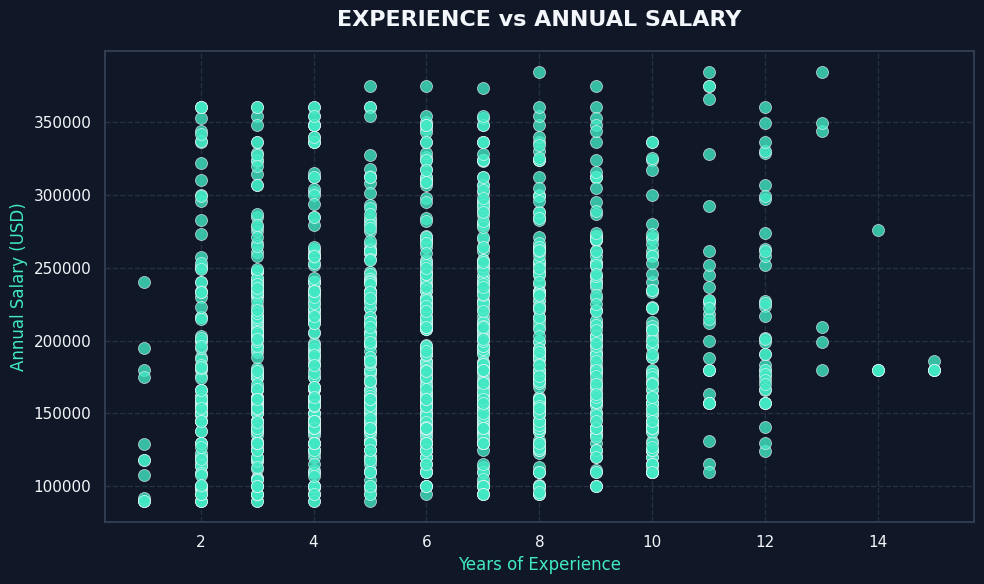

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Custom color palette
BG = "#101827"        # Midnight navy
TEAL = "#42E8C4"      # Electric teal
CORAL = "#FF7F6E"     # Coral
WHITE = "#F3F6FA"     # Soft white
GRID = "#344155"      # Muted grid

sns.set_theme(style="darkgrid")

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

sns.scatterplot(
    x=X["years_of_experience"],
    y=y,
    color=TEAL,
    s=75,
    alpha=0.8,
    edgecolor=WHITE,
    linewidth=0.5,
    ax=ax
)

ax.set_title(
    "EXPERIENCE vs ANNUAL SALARY",
    color=WHITE,
    fontsize=16,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Years of Experience", color=TEAL, fontsize=12)
ax.set_ylabel("Annual Salary (USD)", color=TEAL, fontsize=12)

ax.tick_params(colors=WHITE)
ax.grid(color=GRID, linestyle="--", alpha=0.6)

for spine in ax.spines.values():
    spine.set_color(GRID)

plt.tight_layout()
plt.show()

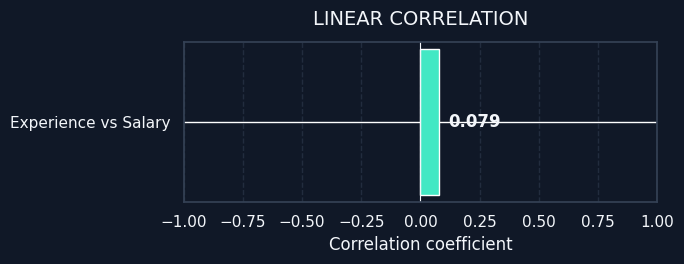

Correlation coefficient: 0.0786


In [21]:
correlation = X["years_of_experience"].corr(y)

fig, ax = plt.subplots(figsize=(7, 2.8))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

ax.barh(
    ["Experience vs Salary"],
    [correlation],
    color=TEAL if correlation >= 0 else CORAL,
    height=0.45
)

ax.set_xlim(-1, 1)
ax.axvline(0, color=WHITE, linewidth=0.8)
ax.set_title("LINEAR CORRELATION", color=WHITE, fontsize=14, pad=12)
ax.set_xlabel("Correlation coefficient", color=WHITE)
ax.tick_params(colors=WHITE)
ax.grid(axis="x", color=GRID, linestyle="--", alpha=0.5)

for spine in ax.spines.values():
    spine.set_color(GRID)

ax.text(
    correlation + (0.04 if correlation >= 0 else -0.04),
    0,
    f"{correlation:.3f}",
    color=WHITE,
    va="center",
    ha="left" if correlation >= 0 else "right",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("Correlation coefficient:", round(correlation, 4))

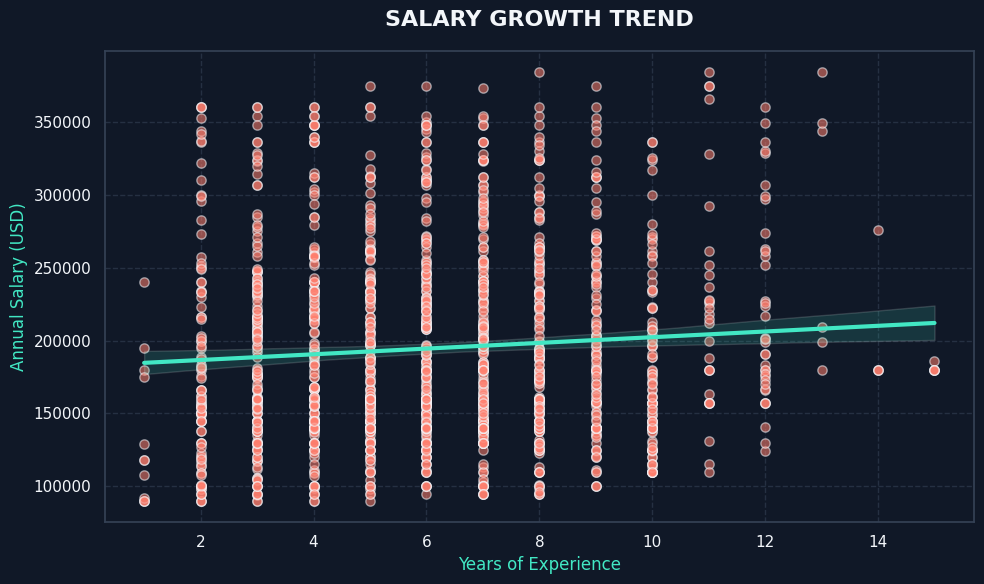

In [23]:
fig, ax = plt.subplots(figsize=(10, 6))

fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

sns.regplot(
    x=X["years_of_experience"],
    y=y,
    color=TEAL,
    ci=95,
    scatter_kws={
        "color": CORAL,
        "alpha": 0.55,
        "s": 45,
        "edgecolor": WHITE
    },
    line_kws={
        "color": TEAL,
        "linewidth": 3
    },
    ax=ax
)

ax.set_title(
    "SALARY GROWTH TREND",
    color=WHITE,
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Years of Experience", color=TEAL, fontsize=12)
ax.set_ylabel("Annual Salary (USD)", color=TEAL, fontsize=12)

ax.tick_params(colors=WHITE)
ax.grid(color=GRID, linestyle="--", alpha=0.6)

for spine in ax.spines.values():
    spine.set_color(GRID)

plt.tight_layout()
plt.show()

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training and testing split completed!")
print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training and testing split completed!
Training input shape: (1200, 1)
Testing input shape: (300, 1)
Training target shape: (1200,)
Testing target shape: (300,)


In [25]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

print("Intercept:", round(model.intercept_, 2))
print("Coefficient:", round(model.coef_[0], 2))

Linear Regression model trained successfully!
Intercept: 178233.49
Coefficient: 2779.98


In [26]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Years of Experience": X_test["years_of_experience"].values,
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred.round(2)
})

display(results.head(10))

,Years of Experience,Actual Salary,Predicted Salary
0,8,233000.0,200473.31
1,8,184000.0,200473.31
2,11,218000.0,208813.24
3,7,244000.0,197693.33
4,12,191000.0,211593.22
5,7,336000.0,197693.33
6,3,240000.0,186573.42
7,8,224000.0,200473.31
8,5,145000.0,192133.38
9,4,145000.0,189353.40


In [27]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("-" * 35)
print(f"MAE  : ${mae:,.2f}")
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : ${rmse:,.2f}")
print(f"R²   : {r2:.4f}")
print(f"R² (%) : {r2 * 100:.2f}%")

MODEL EVALUATION RESULTS
-----------------------------------
MAE  : $54,663.13
MSE  : 4,212,230,768.12
RMSE : $64,901.70
R²   : -0.0276
R² (%) : -2.76%


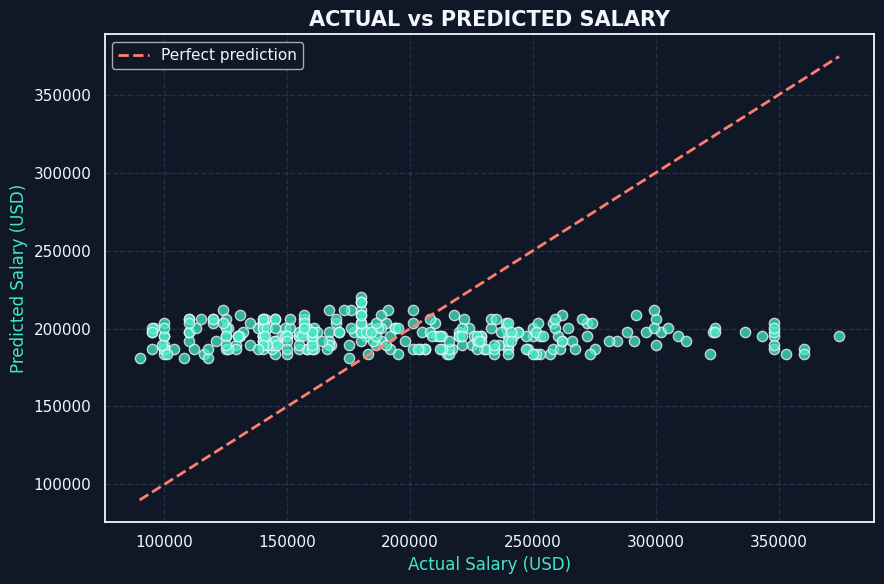

In [28]:
fig, ax = plt.subplots(figsize=(9, 6))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

ax.scatter(
    y_test,
    y_pred,
    color=TEAL,
    alpha=0.75,
    s=55,
    edgecolor=WHITE
)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

ax.plot(
    [lower, upper],
    [lower, upper],
    color=CORAL,
    linewidth=2,
    linestyle="--",
    label="Perfect prediction"
)

ax.set_title(
    "ACTUAL vs PREDICTED SALARY",
    color=WHITE,
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Actual Salary (USD)", color=TEAL)
ax.set_ylabel("Predicted Salary (USD)", color=TEAL)
ax.tick_params(colors=WHITE)
ax.grid(color=GRID, linestyle="--", alpha=0.6)
ax.legend(facecolor=BG, labelcolor=WHITE)

plt.tight_layout()
plt.show()

In [29]:

# Check how strongly experience and salary are related
correlation = X["years_of_experience"].corr(y)

# Check performance on training and testing data
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

# Compare against a simple average-salary baseline
baseline_pred = np.full(len(y_test), y_train.mean())
baseline_r2 = r2_score(y_test, baseline_pred)

print("Correlation between experience and salary:", round(correlation, 4))
print("Training R²:", round(train_r2, 4))
print("Testing R²:", round(test_r2, 4))
print("Average-salary baseline R²:", round(baseline_r2, 4))

# View average salary at each experience level
display(
    df.groupby("years_of_experience")["annual_salary_usd"]
      .mean()
      .reset_index()
      .rename(columns={"annual_salary_usd": "Average Salary (USD)"})
)


Correlation between experience and salary: 0.0786
Training R²: 0.012
Testing R²: -0.0276
Average-salary baseline R²: -0.0022


,years_of_experience,Average Salary (USD)
0,1,135416.666667
1,2,184202.020202
2,3,191632.530120
3,4,195548.192771
4,5,191025.842697
5,6,196006.730769
6,7,199464.974619
7,8,196242.528736
8,9,199996.666667
9,10,179965.306122


In [30]:

# Find numeric columns correlated with annual salary
numeric_df = df.select_dtypes(include="number")

correlations = (
    numeric_df.corr(numeric_only=True)["annual_salary_usd"]
    .drop("annual_salary_usd")
    .sort_values(key=abs, ascending=False)
)

print("Correlation of numeric features with annual salary:")
display(correlations.to_frame("Correlation"))



Correlation of numeric features with annual salary:


,Correlation
is_senior,0.486629
salary_max_usd,0.426631
salary_min_usd,0.421042
demand_score,0.291800
demand_growth_yoy_pct,0.142776
is_llm_role,0.102082
years_of_experience,0.078643
posting_month,-0.024256
posting_year,0.022232
ai_salary_premium_pct,-0.019829


In [31]:

import joblib
from google.colab import files

# Save the trained Simple Linear Regression model
joblib.dump(model, "salary_model.pkl")

print("Model saved successfully as salary_model.pkl")

# Download the model to your computer
files.download("salary_model.pkl")


Model saved successfully as salary_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>